# Figure 5 Reproduction — AP-G vs log₂(MIC)

Reproduces Figure 5 from Olayo-Alarcon et al. (Nature Comms 2025).
- **Step 1**: Original MolE-XGB AP-G scores (verification: expect ρ ≈ −0.5)
- **Step 2**: MolE + GPT-5.2 freeform XGB AP-G scores
- **Step 3**: GPT-5.2 freeform only XGB AP-G scores (no MolE)

In [8]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy import stats

def find_data_dir():
    here = Path().resolve()
    for c in [here / "data", here.parent / "data"]:
        if (c / "prestwick_library_screened.tsv.gz").exists():
            return c
    raise FileNotFoundError("Cannot find data/")

DATA_DIR            = find_data_dir()
ST10_XLS            = DATA_DIR / "mechchem" / "SupplementaryTable10.xlsx"
GPT_SCORES_CSV      = DATA_DIR / "mechchem" / "ap_scores_gpt52.csv"          # mole_plus_gpt
GPT_ONLY_SCORES_CSV = DATA_DIR / "mechchem" / "ap_scores_gpt52_gptonly.csv"  # gpt_only

OUT_DIR = DATA_DIR / "mechchem"
OUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"ST10          : {ST10_XLS}")
print(f"MolE+GPT APs  : {GPT_SCORES_CSV}")
print(f"GPT-only APs  : {GPT_ONLY_SCORES_CSV}")

ST10          : D:\Hiwi\GPT+Mole\GPT+Mole\data\mechchem\SupplementaryTable10.xlsx
MolE+GPT APs  : D:\Hiwi\GPT+Mole\GPT+Mole\data\mechchem\ap_scores_gpt52.csv
GPT-only APs  : D:\Hiwi\GPT+Mole\GPT+Mole\data\mechchem\ap_scores_gpt52_gptonly.csv


## 1. Load & Prepare Data

In [9]:
st10 = pd.read_excel(ST10_XLS, sheet_name="ST 10", header=6)
print(f"ST10 shape: {st10.shape}")

# Filter: MolE-predicted only
mole_df = st10[st10["Predicted by"].str.contains("MolE", na=False)].copy()
print(f"MolE-predicted rows: {len(mole_df)}")

# Melt gram-positive / gram-negative into separate rows
gpos = (
    mole_df[mole_df["MIC_gpositive"].notna()]
    .assign(gram_stain="Positive", MIC=lambda d: d["MIC_gpositive"])
    [["ProductName", "MIC", "gram_stain", "apscore_total.MolE"]]
)
gneg = (
    mole_df[mole_df["MIC_gnegative"].notna()]
    .assign(gram_stain="Negative", MIC=lambda d: d["MIC_gnegative"])
    [["ProductName", "MIC", "gram_stain", "apscore_total.MolE"]]
)
plot_df = pd.concat([gpos, gneg]).query("MIC <= 128").copy()
plot_df["log2_MIC"] = np.log2(plot_df["MIC"])
print(f"Compound-species combinations (MIC <= 128): {len(plot_df)}")
plot_df.head(8)

ST10 shape: (44, 14)
MolE-predicted rows: 36
Compound-species combinations (MIC <= 128): 42


,ProductName,MIC,gram_stain,apscore_total.MolE,log2_MIC
0,Diiodohydroxyquinoline,0.125,Positive,-1.715090,-3.000000
1,Broxyquinoline,0.250,Positive,-1.035615,-2.000000
2,Chlorquinaldol,0.250,Positive,-4.132725,-2.000000
3,Bithionol,0.890,Positive,-0.459424,-0.168123
4,Pralatrexate,0.950,Positive,-4.566516,-0.074001
5,Fenticonazole (Nitrate),1.000,Positive,-4.166968,0.000000
6,(20S)-Protopanaxadiol,1.000,Positive,-5.603265,0.000000
7,(20S)-Protopanaxatriol,1.000,Positive,-6.000750,0.000000


## 2. Plot Function

In [10]:
LABEL_COMPOUNDS = [
    "Diiodohydroxyquinoline",
    "Fenticonazole (Nitrate)",
    "Chlorquinaldol",
    "Mequitazine",
    "Cholesteryl linoleate",
    "Shionone",
]

COLOR_MAP = {"Positive": "#4472C4", "Negative": "#FFC000"}

def plot_fig5(df, score_col, out_path):
    x = df["log2_MIC"].values
    y = df[score_col].values

    rho, pval = stats.spearmanr(x, y)
    slope, intercept, _, slope_p, _ = stats.linregress(x, y)

    fig, ax = plt.subplots(figsize=(7, 5))

    for gram, color in COLOR_MAP.items():
        sub = df[df["gram_stain"] == gram]
        ax.scatter(sub["log2_MIC"], sub[score_col],
                   color=color, s=55, alpha=0.85, zorder=3,
                   edgecolors="white", linewidth=0.4, label=f"Gram {gram}")

    x_line = np.linspace(x.min() - 0.3, x.max() + 0.3, 200)
    y_line = slope * x_line + intercept
    n = len(x)
    x_mean = x.mean()
    se = np.sqrt(np.sum((y - (slope * x + intercept))**2) / (n - 2))
    se_line = se * np.sqrt(1/n + (x_line - x_mean)**2 / np.sum((x - x_mean)**2))

    ax.plot(x_line, y_line, color="#E91E8C", linewidth=2, zorder=4)
    ax.fill_between(x_line, y_line - 1.96*se_line, y_line + 1.96*se_line,
                    color="gray", alpha=0.2, zorder=2)

    labeled = set()
    for _, row in df.iterrows():
        if row["ProductName"] in LABEL_COMPOUNDS and row["ProductName"] not in labeled:
            ax.annotate(
                row["ProductName"],
                xy=(row["log2_MIC"], row[score_col]),
                xytext=(row["log2_MIC"] + 0.4, row[score_col] + 0.4),
                fontsize=7.5, color="#222222",
                arrowprops=dict(arrowstyle="->", color="#555555", lw=0.8),
                bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.7, lw=0)
            )
            labeled.add(row["ProductName"])

    ax.set_title(f"Spearman ρ: {rho:.3f} (p-value: {pval:.4f})", fontsize=11)
    ax.text(0.04, 0.04, f"Slope: {slope:.3f} (p-value: {slope_p:.4f})",
            transform=ax.transAxes, fontsize=9,
            bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.8))
    ax.set_xlabel("log₂(MIC)", fontsize=11)
    ax.set_ylabel("Antimicrobial Potential G", fontsize=11)

    legend_handles = [mpatches.Patch(color=c, label=f"Gram {g}")
                      for g, c in COLOR_MAP.items()]
    ax.legend(handles=legend_handles, title="Gram stain", fontsize=9, title_fontsize=9)

    plt.tight_layout()
    plt.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved: {out_path}")
    return rho, pval, slope, slope_p

print("plot_fig5() defined.")

plot_fig5() defined.


## 3. Step 1 — Original MolE-XGB Scores (Verification)

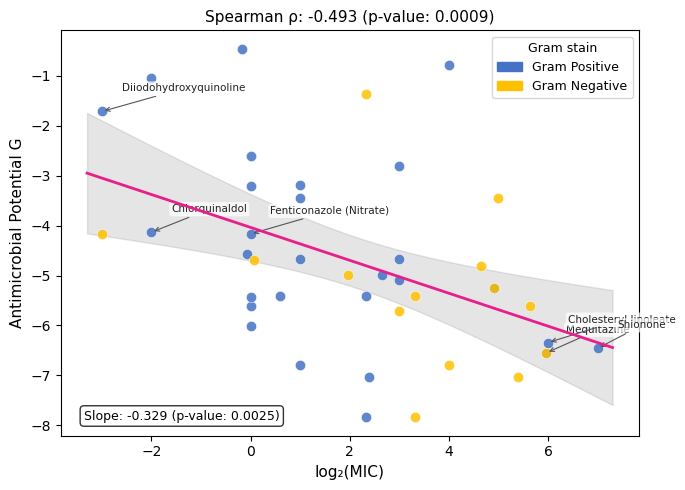

Saved: D:\Hiwi\GPT+Mole\GPT+Mole\data\mechchem\fig5_original.png

MolE-XGB: Spearman rho=-0.4926  p=0.0009  slope=-0.3294  slope_p=0.0025
Expected: rho ≈ -0.5,  p ≈ 0.001,  slope ≈ -0.34


In [11]:
rho1, pval1, slope1, sp1 = plot_fig5(
    plot_df, "apscore_total.MolE",
    OUT_DIR / "fig5_original.png"
)
print(f"\nMolE-XGB: Spearman rho={rho1:.4f}  p={pval1:.4f}  slope={slope1:.4f}  slope_p={sp1:.4f}")
print(f"Expected: rho ≈ -0.5,  p ≈ 0.001,  slope ≈ -0.34")

## 4. Step 2 — MolE + GPT-5.2 Freeform XGB Scores

GPT AP scores loaded: (29, 2)
              ProductName  ap_score_gpt
0   (20S)-Protopanaxadiol     -4.163829
1              Simeprevir     -1.735759
2  (20S)-Protopanaxatriol     -3.934666
3              Telaprevir     -2.198745
4              Everolimus     -2.271567
Matched compound-species rows: 38


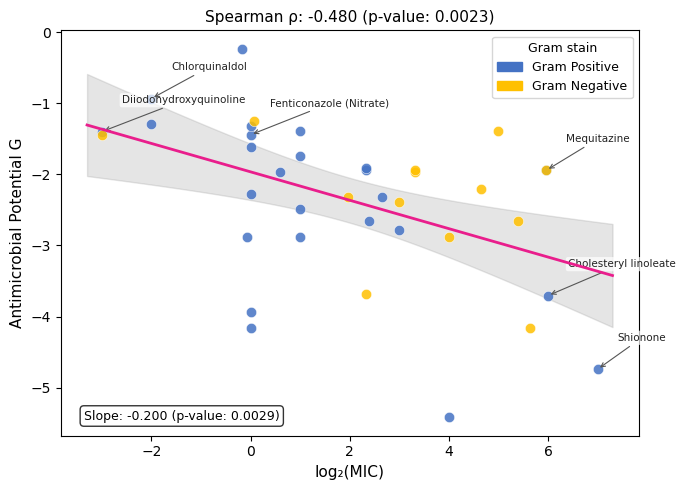

Saved: D:\Hiwi\GPT+Mole\GPT+Mole\data\mechchem\fig5_gpt_scores.png

                      Spearman rho     p-value     slope     slope p
MolE-XGB                   -0.4926      0.0009   -0.3294      0.0025
GPT-XGB                    -0.4802      0.0023   -0.1998      0.0029


In [12]:
if not GPT_SCORES_CSV.exists():
    print(f"[SKIP] {GPT_SCORES_CSV} not found.")
    print("Run build_train.py with --ap_score_compounds to generate it.")
else:
    gpt_scores = pd.read_csv(GPT_SCORES_CSV)
    print(f"GPT AP scores loaded: {gpt_scores.shape}")
    print(gpt_scores.head())

    plot_df2 = plot_df.merge(
        gpt_scores[["ProductName", "ap_score_gpt"]],
        on="ProductName", how="inner"
    )
    print(f"Matched compound-species rows: {len(plot_df2)}")

    rho2, pval2, slope2, sp2 = plot_fig5(
        plot_df2, "ap_score_gpt",
        OUT_DIR / "fig5_gpt_scores.png"
    )

    print("\n" + "="*65)
    print(f"{'':<20}  {'Spearman rho':>12}  {'p-value':>10}  {'slope':>8}  {'slope p':>10}")
    print(f"{'MolE-XGB':<20}  {rho1:>12.4f}  {pval1:>10.4f}  {slope1:>8.4f}  {sp1:>10.4f}")
    print(f"{'GPT-XGB':<20}  {rho2:>12.4f}  {pval2:>10.4f}  {slope2:>8.4f}  {sp2:>10.4f}")
    print("="*65)

## 5. Step 3 — GPT-5.2 Freeform Only XGB Scores (no MolE)

GPT-only AP scores loaded: (29, 2)
              ProductName  ap_score_gpt
0   (20S)-Protopanaxadiol     -2.729633
1              Simeprevir     -0.612751
2  (20S)-Protopanaxatriol     -3.079758
3              Telaprevir     -1.126140
4              Everolimus     -2.387548
Matched compound-species rows: 38


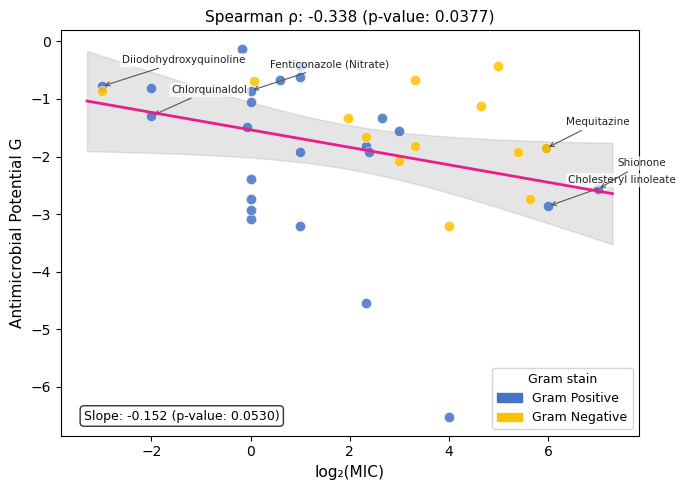

Saved: D:\Hiwi\GPT+Mole\GPT+Mole\data\mechchem\fig5_gpt_only_scores.png

                           Spearman rho     p-value     slope     slope p
----------------------------------------------------------------------
MolE-XGB (paper)                -0.4926      0.0009   -0.3294      0.0025
MolE + GPT-5.2 XGB              -0.4802      0.0023   -0.1998      0.0029
GPT-5.2 only XGB                -0.3384      0.0377   -0.1518      0.0530


In [13]:
if not GPT_ONLY_SCORES_CSV.exists():
    print(f"[SKIP] {GPT_ONLY_SCORES_CSV} not found.")
    print("Run: compute_ap_scores(model_pkl_path='results/freeform/gpt-5.2/xgb_model_gpt_only.pkl', ...)")
else:
    gpt_only_scores = pd.read_csv(GPT_ONLY_SCORES_CSV)
    print(f"GPT-only AP scores loaded: {gpt_only_scores.shape}")
    print(gpt_only_scores.head())

    # rename column for plot_fig5
    gpt_only_scores = gpt_only_scores.rename(columns={"ap_score_gpt": "ap_score_gptonly"})

    plot_df3 = plot_df.merge(
        gpt_only_scores[["ProductName", "ap_score_gptonly"]],
        on="ProductName", how="inner"
    )
    print(f"Matched compound-species rows: {len(plot_df3)}")

    rho3, pval3, slope3, sp3 = plot_fig5(
        plot_df3, "ap_score_gptonly",
        OUT_DIR / "fig5_gpt_only_scores.png"
    )

    # --- full 3-model comparison table ---
    print("\n" + "="*70)
    print(f"{'':<25}  {'Spearman rho':>12}  {'p-value':>10}  {'slope':>8}  {'slope p':>10}")
    print("-"*70)
    try:
        print(f"{'MolE-XGB (paper)':<25}  {rho1:>12.4f}  {pval1:>10.4f}  {slope1:>8.4f}  {sp1:>10.4f}")
    except NameError:
        print("  [run Step 1 first to get rho1]")
    try:
        print(f"{'MolE + GPT-5.2 XGB':<25}  {rho2:>12.4f}  {pval2:>10.4f}  {slope2:>8.4f}  {sp2:>10.4f}")
    except NameError:
        print("  [run Step 2 first to get rho2]")
    print(f"{'GPT-5.2 only XGB':<25}  {rho3:>12.4f}  {pval3:>10.4f}  {slope3:>8.4f}  {sp3:>10.4f}")
    print("="*70)

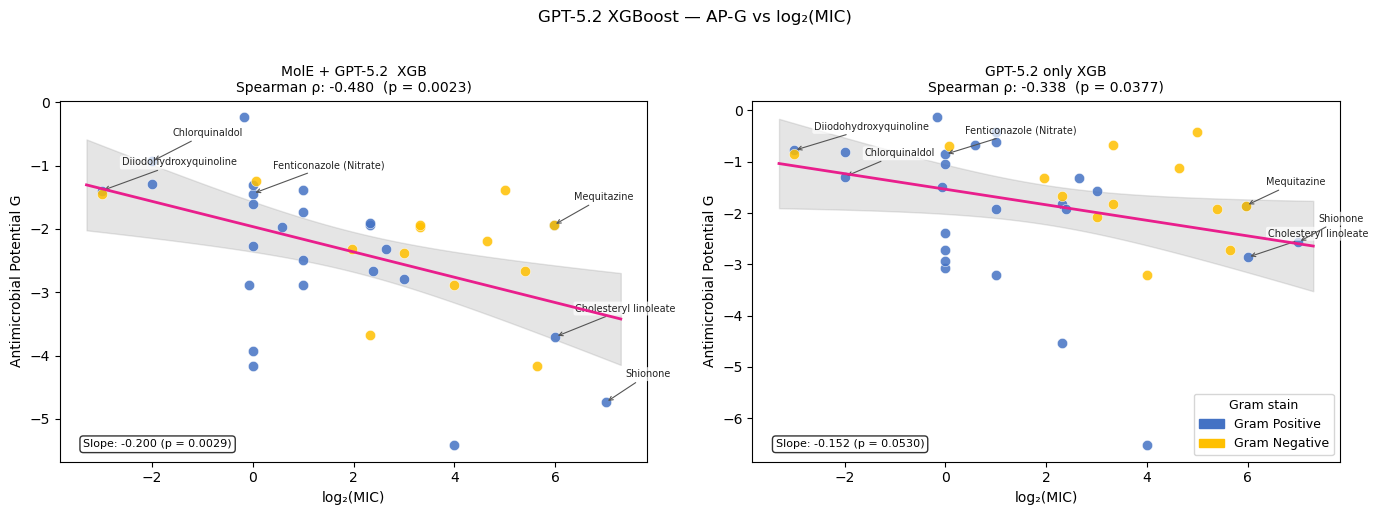

Saved: D:\Hiwi\GPT+Mole\GPT+Mole\data\mechchem\fig5_comparison.png


In [14]:
# Side-by-side: MolE + GPT-5.2  vs  GPT-5.2 only
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)

panels = [
    (plot_df2,  "ap_score_gpt",     "MolE + GPT-5.2  XGB",  rho2, pval2, slope2, sp2),
    (plot_df3,  "ap_score_gptonly", "GPT-5.2 only XGB",     rho3, pval3, slope3, sp3),
]

for ax, (df, score_col, title, rho, pval, slope, slope_p) in zip(axes, panels):
    x = df["log2_MIC"].values
    y = df[score_col].values

    for gram, color in COLOR_MAP.items():
        sub = df[df["gram_stain"] == gram]
        ax.scatter(sub["log2_MIC"], sub[score_col],
                   color=color, s=55, alpha=0.85, zorder=3,
                   edgecolors="white", linewidth=0.4, label=f"Gram {gram}")

    x_line = np.linspace(x.min() - 0.3, x.max() + 0.3, 200)
    y_line = slope * x_line + slope_p  # recompute properly
    slope_val, intercept, *_ = stats.linregress(x, y)
    y_line = slope_val * x_line + intercept
    n, x_mean = len(x), x.mean()
    se = np.sqrt(np.sum((y - (slope_val * x + intercept))**2) / (n - 2))
    se_line = se * np.sqrt(1/n + (x_line - x_mean)**2 / np.sum((x - x_mean)**2))

    ax.plot(x_line, y_line, color="#E91E8C", linewidth=2, zorder=4)
    ax.fill_between(x_line, y_line - 1.96*se_line, y_line + 1.96*se_line,
                    color="gray", alpha=0.2, zorder=2)

    labeled = set()
    for _, row in df.iterrows():
        if row["ProductName"] in LABEL_COMPOUNDS and row["ProductName"] not in labeled:
            ax.annotate(
                row["ProductName"],
                xy=(row["log2_MIC"], row[score_col]),
                xytext=(row["log2_MIC"] + 0.4, row[score_col] + 0.4),
                fontsize=7, color="#222222",
                arrowprops=dict(arrowstyle="->", color="#555555", lw=0.8),
                bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.7, lw=0)
            )
            labeled.add(row["ProductName"])

    ax.set_title(f"{title}\nSpearman ρ: {rho:.3f}  (p = {pval:.4f})", fontsize=10)
    ax.text(0.04, 0.04, f"Slope: {slope:.3f} (p = {slope_p:.4f})",
            transform=ax.transAxes, fontsize=8,
            bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.8))
    ax.set_xlabel("log₂(MIC)", fontsize=10)
    ax.set_ylabel("Antimicrobial Potential G", fontsize=10)

legend_handles = [mpatches.Patch(color=c, label=f"Gram {g}") for g, c in COLOR_MAP.items()]
axes[1].legend(handles=legend_handles, title="Gram stain", fontsize=9, title_fontsize=9)

plt.suptitle("GPT-5.2 XGBoost — AP-G vs log₂(MIC)", fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig(OUT_DIR / "fig5_comparison.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {OUT_DIR / 'fig5_comparison.png'}")